In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [13]:
file1 = np.loadtxt("C:/Users/tomsh/OneDrive - University of Leeds/year 4/Accretion disc/Semester 2/Week3/Retrograde_cer/gwdisc01_ret.ev")

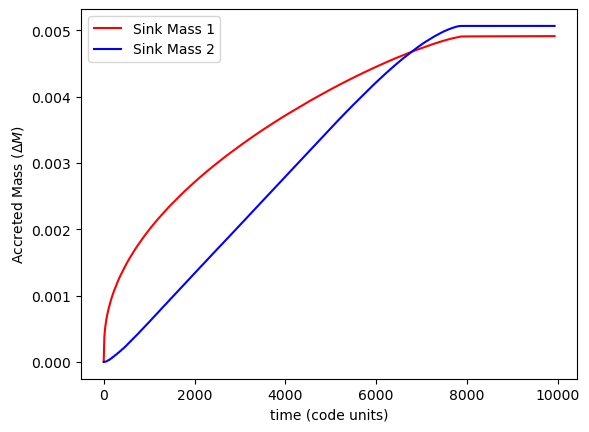

In [14]:
mass_acc1 = file1[:,20]
mass_acc2 = file1[:,21]
time1 = file1[:,0]
plt.plot(time1,mass_acc1, '-', color = 'red', label = 'Sink Mass 1')
plt.plot(time1,mass_acc2,'-',color = 'blue',label = 'Sink Mass 2')
plt.xlabel('time (code units)')
plt.ylabel('Accreted Mass ($\Delta{M}$)')
plt.legend()
plt.savefig("GW_Cerioli_sim_retrograde.png")
plt.show()

In [15]:
def Mass_Acc_rate(M,time):
    """
    input:
    
    M - mass accreted onto hole at a certain time
    t - the time within the simulation in code units

    Reads data points and subtracts the previous value from the current datapoint to find the mass 
    accretion rate at that current time

    output:
    Returns the mass accretion rate of a black hole 
    """

    dt = np.diff(time)
    dM = np.diff(M)

    Mdot = dM / dt
    t_mid = 0.5 * (time[1:] + time[:-1])

    return t_mid, Mdot
    
    

In [16]:
def Mass_acc_rate_graph_Primary(filename,Mdisc=1):
    """
    """
    file = np.loadtxt(filename)
    mass_acc1 = file[:,20]
    
    time = file[:,0]
    t_mid, Mdot = Mass_Acc_rate(mass_acc1,time)
    Mdotnorm = Mdot/Mdisc
    return t_mid, Mdotnorm

In [17]:
def Mass_acc_rate_graph_Secondary(filename, Mdisc=1):
    """
    """
    file = np.loadtxt(filename)
    mass_acc2 = file[:,21]
    
    time = file[:,0]
    t_mid, Mdot2 = Mass_Acc_rate(mass_acc2,time)
    Mdotnorm2 = Mdot2/Mdisc
    return t_mid, Mdot2

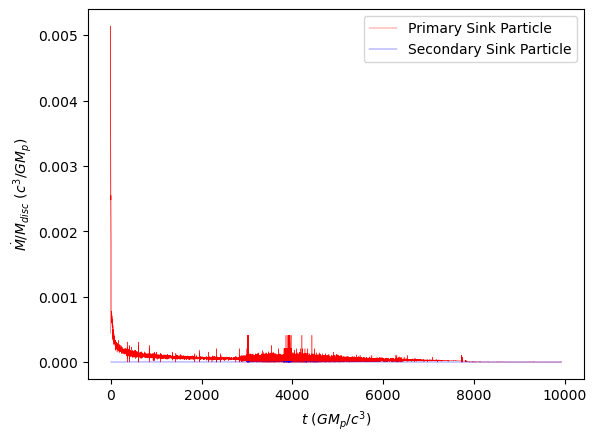

In [19]:
tmidP, MdotP = Mass_acc_rate_graph_Primary("C:/Users/tomsh/OneDrive - University of Leeds/year 4/Accretion disc/Semester 2/Week3/Retrograde_cer/gwdisc01_ret.ev",0.01)
tmidS, MdotS = Mass_acc_rate_graph_Secondary("C:/Users/tomsh/OneDrive - University of Leeds/year 4/Accretion disc/Semester 2/Week3/Retrograde_cer/gwdisc01_ret.ev",0.01)
plt.plot(tmidP, MdotP, '-', color = 'red', linewidth = 0.3,label = "Primary Sink Particle")
plt.plot(tmidS, MdotS, '-', color = 'blue', linewidth = 0.3, label = "Secondary Sink Particle")
plt.ylabel("$\dot{M}$/$M_{disc}$ ($c^3$/$GM_p$)")
plt.xlabel ("$t$ ($GM_p$/$c^3$)")
plt.legend()
plt.savefig("Retrograde_accretrion_rate_Cer.png")
plt.show()
